# NN_L13_mae_by_hour

**Mean absolute error by delivery hour of the naive, LEAR, DNN, Chronos-2 and ensemble forecasts of Romanian day-ahead prices in the test year.**

Neural Networks and Deep Learning (NN), Lecture 13 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L13/NN_L13_mae_by_hour/NN_L13_mae_by_hour.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

LEAR worst hourly MAE = 35.78   [byhour.lear.worst]
LEAR worst hour = 19   [byhour.lear.worst_hour]
Chronos-2 worst hourly MAE = 34.05   [byhour.chronos2.worst]


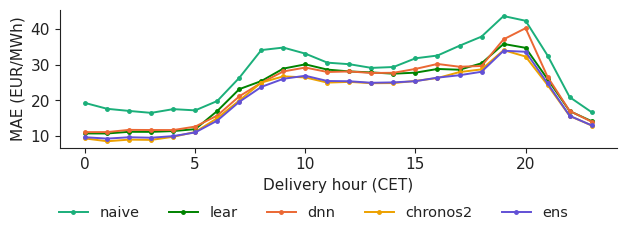

In [3]:
RES = REPO + 'lectures/L13/results/'
F = pd.read_csv(RES + 'forecasts_hourly.csv', parse_dates=['date'])
MODELS = ['naive', 'lear', 'dnn', 'nbeats', 'chronos2', 'chronos2_cov', 'bolt', 'timesfm', 'ens']
E = {m: (F[m] - F['actual']).abs().groupby(F['hour']).mean() for m in ['naive', 'lear', 'dnn', 'chronos2', 'ens']}
show('byhour.lear.worst', 'LEAR worst hourly MAE', round(float(E['lear'].max()), 2))
show('byhour.lear.worst_hour', 'LEAR worst hour', int(E['lear'].idxmax()))
show('byhour.chronos2.worst', 'Chronos-2 worst hourly MAE', round(float(E['chronos2'].max()), 2))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
for m, c in zip(E, [PAL['benchmark'], SERIES[5], PAL['model'], PAL['alt'], '#6250d6']):
    ax.plot(range(24), E[m].values, marker='o', ms=2.5, color=c, label=m)
ax.set_xlabel('Delivery hour (CET)')
ax.set_ylabel('MAE (EUR/MWh)')
legend_bottom(fig, ncol=5)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('mae_by_hour.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()